In [ ]:
!pip -q install pandas numpy nltk matplotlib wordcloud \
    scikit-learn pyLDAvis seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.3 MB/s eta 0:00:00


In [ ]:
import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import pyLDAvis
import pyLDAvis.lda_model

from wordcloud import WordCloud
from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from IPython.display import display

warnings.filterwarnings("ignore")

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("All libraries imported successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully!


In [ ]:
# Download the dataset from GitHub
!git clone https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing.git

# Find CSV and JSON files
dataset_path = (
    "/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing"
)

csv_files = glob.glob(dataset_path + "/**/*.csv", recursive=True)
json_files = glob.glob(dataset_path + "/**/*.json", recursive=True)

print("CSV files found:", csv_files)
print("JSON files found:", json_files)

# Load the first available dataset file
if csv_files:
    df = pd.read_csv(csv_files[0])
elif json_files:
    df = pd.read_json(json_files[0])
else:
    raise FileNotFoundError(
        "No CSV or JSON dataset found in the downloaded repository."
    )

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Cloning into 'Health-Related-Headlines-Datasets-for-Natural-Language-Processing'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 107 (delta 0), reused 2 (delta 0), pack-reused 103 (from 1)
Receiving objects: 100% (107/107), 13.13 MiB | 14.66 MiB/s, done.
Resolving deltas: 100% (43/43), done.
CSV files found: ['/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_Management_Related_Headlines.csv', '/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Substance_Abuse_and_Addiction_News_Headlines.csv', '/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Patient_Safety_Related_Headlines.csv', '/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Peadiatric_Immunization_Features_Headlines.csv', '/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Antibiotic_Resistance_News_Hea

,Date,Source,Headlines,Teaser
0,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...
1,"June, 2001",Medscape Pharmacotherapy,MEDLINE Abstracts: Chronic Nonmalignant Back Pain,A collection of MEDLINE abstracts from the edi...
2,"November, 2001",Journal of the Southern Orthopaedic Association,Isthmic Spondylolisthesis and Spondylolysis,Despite the large number of treatment options ...
3,"December, 2001",Current Medical Research and Opinion,Cizolirtine Citrate in the Treatment of Chroni...,Learn more about a novel non-opioid analgesic ...
4,"February, 2002",Pharmacotherapy,Management of Opioid-Induced Gastrointestinal ...,Awareness of side effects when managing pain w...


In [ ]:
# Identify text columns in the dataset
text_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["headline", "title", "teaser", "text", "article"])
]

# Fallback if column names do not match common text-field names
if not text_columns:
    text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()

if not text_columns:
    raise ValueError("No text columns found in the dataset.")

print("Text columns selected:", text_columns)

# Combine available text columns into one column
df["combined_text"] = (
    df[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# Remove empty records
df = df[df["combined_text"].str.len() > 0].copy()

# Initialize preprocessing tools
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Lowercasing
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove numbers and punctuation
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stop-word removal and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return cleaned_tokens

# Store tokens and cleaned text
df["tokens"] = df["combined_text"].apply(clean_text)
df["cleaned_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))

# Remove records that become empty after cleaning
df = df[df["cleaned_text"].str.strip().ne("")].copy()
df.reset_index(drop=True, inplace=True)

print("Preprocessing completed!")
print("\nOriginal and cleaned samples:")

display(df[["combined_text", "cleaned_text"]].head(10))

Text columns selected: ['Headlines', 'Teaser']
Preprocessing completed!

Original and cleaned samples:


,combined_text,cleaned_text
0,Magnet Treatment Had No Beneficial Effect on P...,magnet treatment beneficial effect patient chr...
1,MEDLINE Abstracts: Chronic Nonmalignant Back P...,medline abstract chronic nonmalignant back pai...
2,Isthmic Spondylolisthesis and Spondylolysis De...,isthmic spondylolisthesis spondylolysis despit...
3,Cizolirtine Citrate in the Treatment of Chroni...,cizolirtine citrate treatment chronic neuropa ...
4,Management of Opioid-Induced Gastrointestinal ...,management opioid induced gastrointestinal eff...
5,The Pitfalls of Opioids for Chronic Nonmaligna...,pitfall opioids chronic nonmalignant pain abus...
6,Case 11: Could This Be Guillain-Barre Syndrome...,case could guillain barre syndrome wrong toddler
7,Ketorolac for Pain Management Could a simple N...,ketorolac pain management could simple nsaid u...
8,Aseptic Meningitis Cases Linked to Rofecoxib R...,aseptic meningitis case linked rofecoxib recov...
9,New Guideline for Arthritis Pain Emphasizes Ea...,new guideline arthritis pain emphasizes earlie...


Top 20 most frequent words:


,Word,Frequency
0,pain,4431
1,patient,3393
2,new,1620
3,opioid,1574
4,treatment,1513
5,study,1405
6,use,1207
7,drug,1150
8,may,1085
9,risk,1046


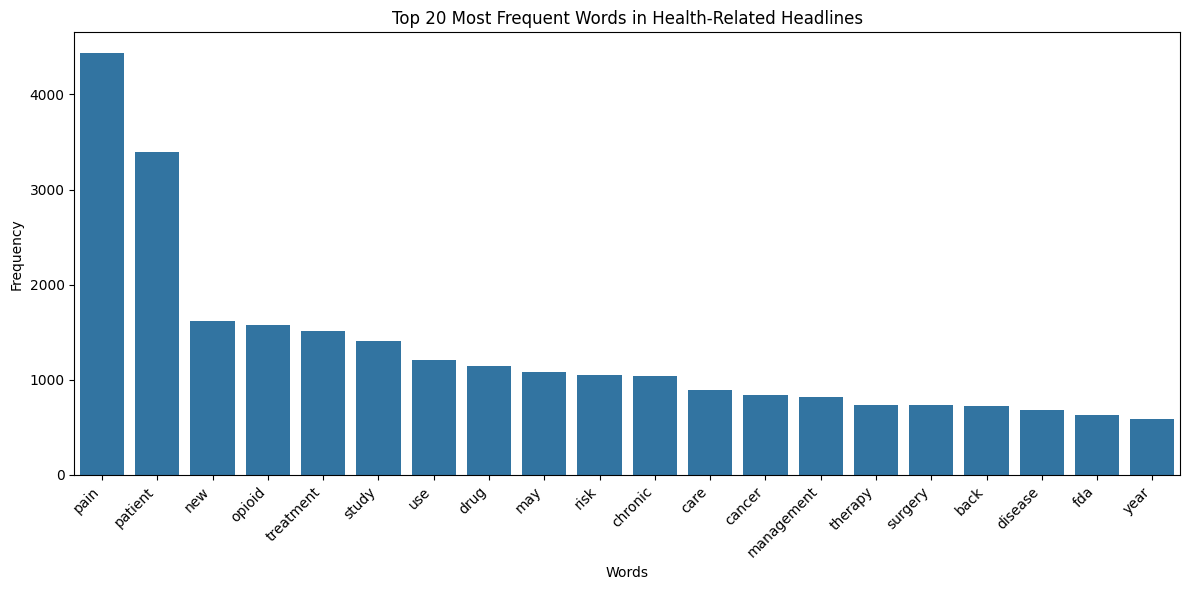

In [ ]:
# Combine all tokens
all_words = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

# Calculate word frequencies
word_freq = Counter(all_words)

# Display the top 20 frequent words
top_20_words = word_freq.most_common(20)

frequency_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

print("Top 20 most frequent words:")
display(frequency_df)

# Plot word frequency distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    data=frequency_df,
    x="Word",
    y="Frequency"
)

plt.title("Top 20 Most Frequent Words in Health-Related Headlines")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

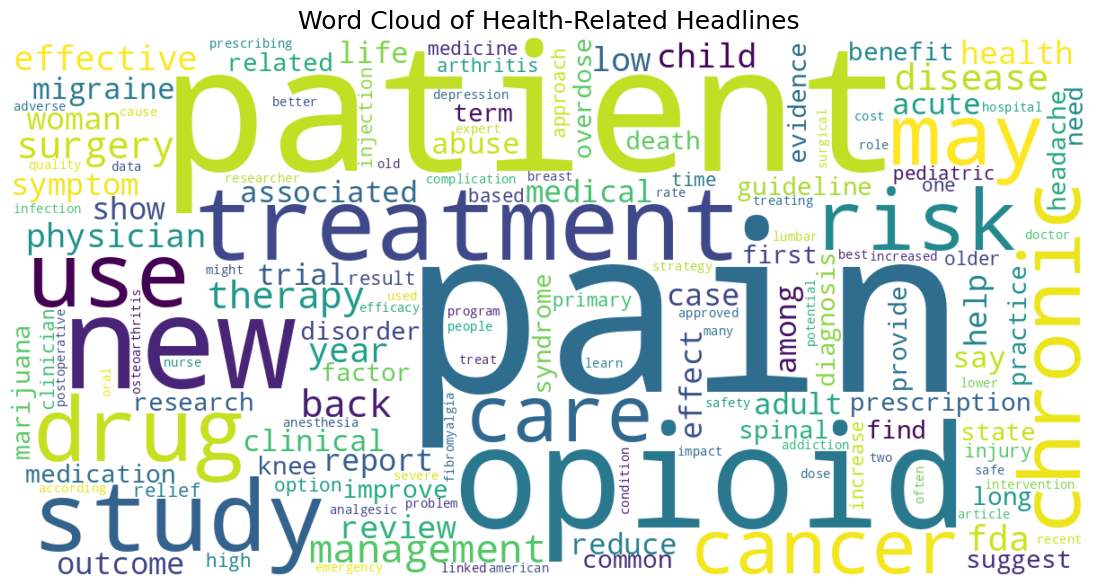

In [ ]:
# Create a word cloud from cleaned text
all_text = " ".join(df["cleaned_text"])

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    collocations=False
).generate(all_text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Headlines", fontsize=18)
plt.show()

In [ ]:
# Convert cleaned documents into a document-term matrix
vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2,
    max_features=5000
)

dtm = vectorizer.fit_transform(df["cleaned_text"])

print("Document-term matrix shape:", dtm.shape)
print("Number of documents:", dtm.shape[0])
print("Number of unique terms:", dtm.shape[1])

# Train LDA model
NUM_TOPICS = 5

lda_model = LatentDirichletAllocation(
    n_components=NUM_TOPICS,
    random_state=42,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(dtm)

print("\nLDA model trained successfully!")

Document-term matrix shape: (9195, 5000)
Number of documents: 9195
Number of unique terms: 5000

LDA model trained successfully!


In [ ]:
feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

Topic 1: pain, patient, back, chronic, low
Topic 2: opioid, drug, use, fda, risk
Topic 3: treatment, patient, disease, migraine, new
Topic 4: patient, care, pain, cancer, physician
Topic 5: surgery, patient, study, pain, child


In [ ]:
# Obtain topic probabilities for every document
topic_probabilities = lda_model.transform(dtm)

# Assign the topic with the highest probability
df["dominant_topic"] = topic_probabilities.argmax(axis=1) + 1

# Store each document's topic probabilities
for i in range(NUM_TOPICS):
    df[f"topic_{i + 1}_probability"] = topic_probabilities[:, i]

print("Document topic assignments:")
display(df[["cleaned_text", "dominant_topic"]].head(10))

print("\nNumber of documents assigned to each topic:")
display(
    df["dominant_topic"]
    .value_counts()
    .sort_index()
    .rename_axis("Topic")
    .reset_index(name="Document Count")
)

Document topic assignments:


,cleaned_text,dominant_topic
0,magnet treatment beneficial effect patient chr...,1
1,medline abstract chronic nonmalignant back pai...,3
2,isthmic spondylolisthesis spondylolysis despit...,3
3,cizolirtine citrate treatment chronic neuropa ...,3
4,management opioid induced gastrointestinal eff...,3
5,pitfall opioids chronic nonmalignant pain abus...,4
6,case could guillain barre syndrome wrong toddler,3
7,ketorolac pain management could simple nsaid u...,1
8,aseptic meningitis case linked rofecoxib recov...,3
9,new guideline arthritis pain emphasizes earlie...,3



Number of documents assigned to each topic:


,Topic,Document Count
0,1,1887
1,2,2125
2,3,1806
3,4,1782
4,5,1595


In [ ]:
# Prepare the interactive pyLDAvis visualization
vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    sort_topics=False
)

# Display in Google Colab
pyLDAvis.enable_notebook()
display(vis)

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.104209  0.160346       1        1  21.020882
1     -0.252855  0.061294       2        1  23.574773
2      0.031951 -0.087651       3        1  19.003854
3      0.009037 -0.162384       4        1  19.086809
4      0.107658  0.028396       5        1  17.313682, topic_info=        Term         Freq        Total Category  logprob  loglift
3185    pain  4323.000000  4323.000000  Default  30.0000  30.0000
3096  opioid  1517.000000  1517.000000  Default  29.0000  29.0000
1351    drug  1109.000000  1109.000000  Default  28.0000  28.0000
657     care   877.000000   877.000000  Default  27.0000  27.0000
423     back   706.000000   706.000000  Default  26.0000  26.0000
...      ...          ...          ...      ...      ...      ...
216    among   108.131491   380.110814   Topic5  -5.5815   0.4966
2135  impact    98.735447   243.972293   Topic5  -5.6724   0.8491
1993    help   108.220747   439.948939   Topic5  -5.5807   0.3512
113    adult   105.502088   375.223415   Topic5  -5.6061   0.4849
1409  effect   101.681730   447.297575   Topic5  -5.6430   0.2723

[374 rows x 6 columns], token_table=      Topic      Freq           Term
term                                
18        5  0.982050     abstinence
20        2  0.997677          abuse
25        4  0.102827        academy
25        5  0.891169        academy
45        2  0.995363  acetaminophen
...     ...       ...            ...
4980      3  0.055734           year
4980      4  0.546887           year
4980      5  0.031350           year
4994      3  0.981216           zika
4999      1  0.975221         zoster

[718 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

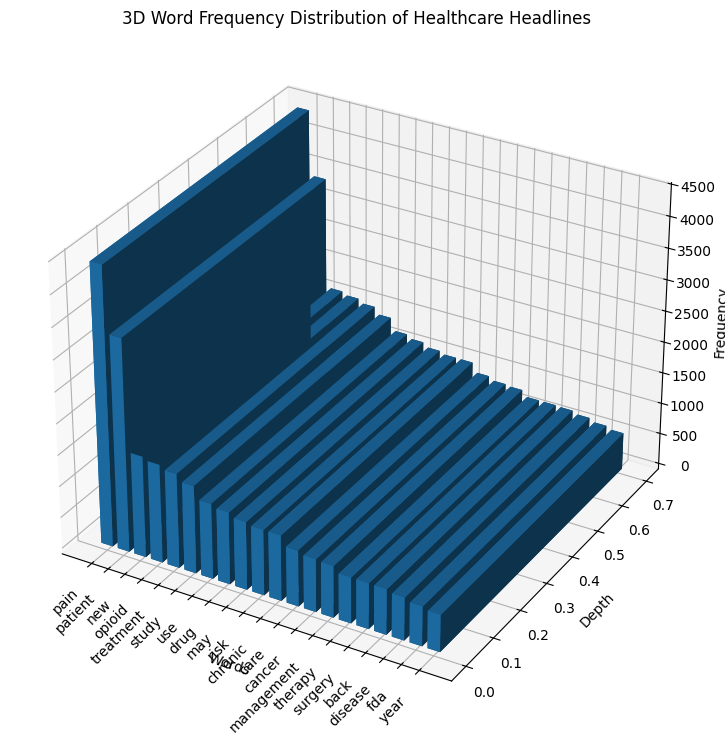

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Select top 20 words
plot_df = frequency_df.head(20).copy()

words = plot_df["Word"].tolist()
frequencies = plot_df["Frequency"].to_numpy()
x = np.arange(len(words))

# Create 3D bar chart
fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(111, projection="3d")

bars = ax.bar3d(
    x, np.zeros(len(x)), np.zeros(len(x)),
    0.7, 0.7, frequencies,
    shade=True,
    cmap="viridis"
)

ax.set_xticks(x + 0.35)
ax.set_xticklabels(words, rotation=45, ha="right")
ax.set_xlabel("Words")
ax.set_ylabel("Depth")
ax.set_zlabel("Frequency")
ax.set_title("3D Word Frequency Distribution of Healthcare Headlines")

plt.tight_layout()
plt.show()

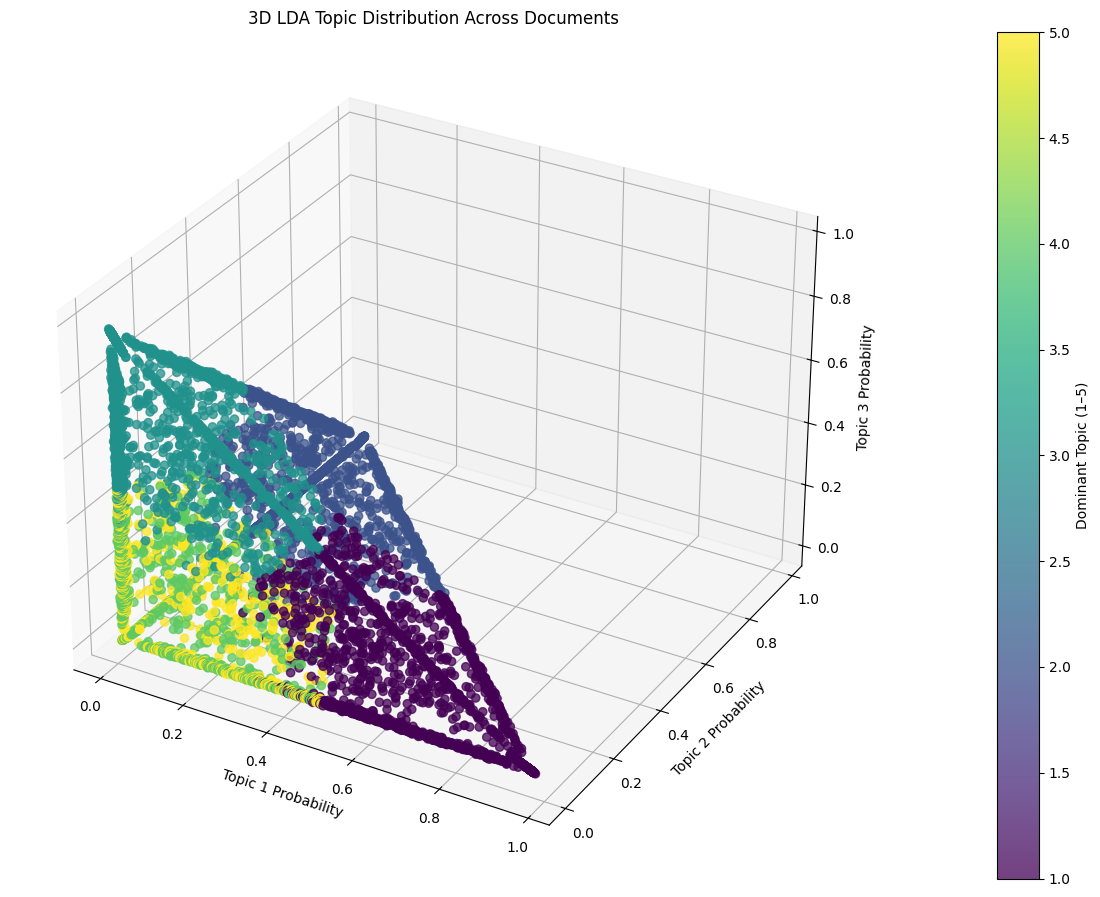

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Use the topic probabilities calculated by the LDA model
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    topic_probabilities[:, 0],
    topic_probabilities[:, 1],
    topic_probabilities[:, 2],
    c=df["dominant_topic"],
    cmap="viridis",
    s=35,
    alpha=0.75
)

ax.set_xlabel("Topic 1 Probability")
ax.set_ylabel("Topic 2 Probability")
ax.set_zlabel("Topic 3 Probability")
ax.set_title("3D LDA Topic Distribution Across Documents")

colorbar = fig.colorbar(scatter, ax=ax, pad=0.12)
colorbar.set_label("Dominant Topic (1–5)")

plt.tight_layout()
plt.show()

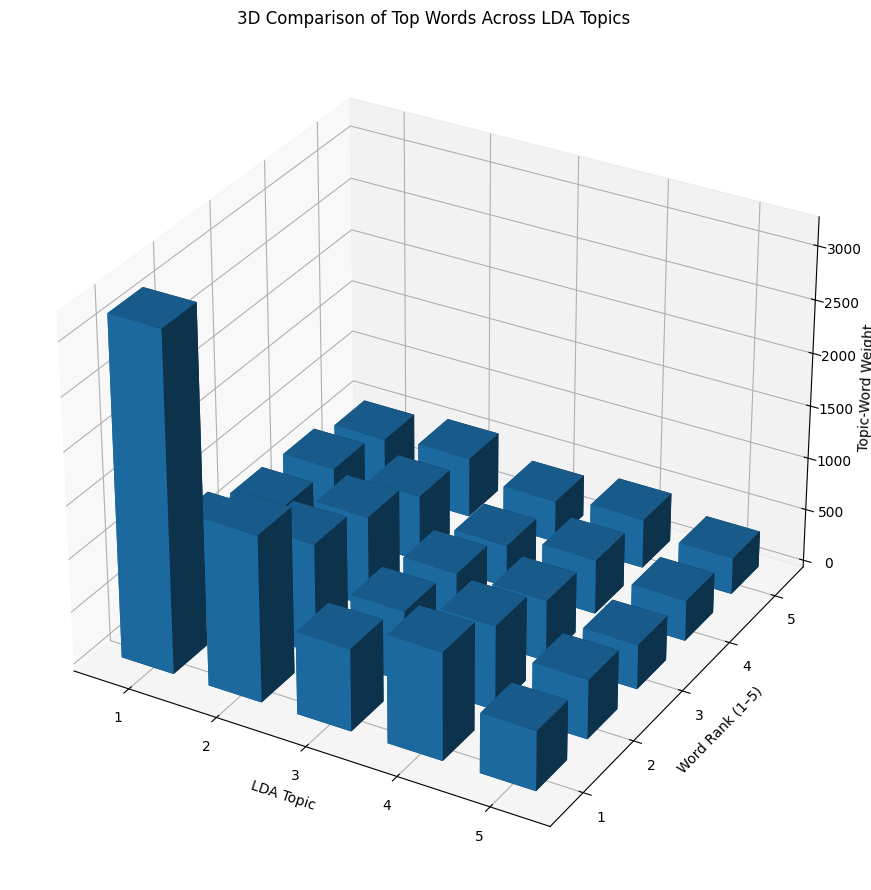

,Topic,Word Rank,Word,Weight
0,1,1,pain,3198.831775
1,1,2,patient,883.928266
2,1,3,back,695.630348
3,1,4,chronic,651.334515
4,1,5,low,518.486361
5,2,1,opioid,1570.853959
6,2,2,drug,1044.790357
7,2,3,use,862.459400
8,2,4,fda,630.942953
9,2,5,risk,571.387174


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

NUM_TOPICS = lda_model.n_components
TOP_WORDS = 5

topic_labels = []
word_labels = []
word_weights = []

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-TOP_WORDS:][::-1]

    for rank, idx in enumerate(top_indices, start=1):
        topic_labels.append(topic_idx + 1)
        word_labels.append(feature_names[idx])
        word_weights.append(topic[idx])

# Convert to arrays
topic_labels = np.array(topic_labels)
word_weights = np.array(word_weights)

# Rank words from 1 to 5 within each topic
word_ranks = np.tile(np.arange(1, TOP_WORDS + 1), NUM_TOPICS)

# Create 3D plot
fig = plt.figure(figsize=(15, 9))
ax = fig.add_subplot(111, projection="3d")

ax.bar3d(
    topic_labels - 0.3,
    word_ranks - 0.3,
    np.zeros(len(word_weights)),
    0.6,
    0.6,
    word_weights,
    shade=True,
    cmap="plasma"
)

ax.set_xticks(range(1, NUM_TOPICS + 1))
ax.set_xlabel("LDA Topic")
ax.set_ylabel("Word Rank (1–5)")
ax.set_zlabel("Topic-Word Weight")
ax.set_title("3D Comparison of Top Words Across LDA Topics")

plt.tight_layout()
plt.show()

# Display the corresponding words and weights
topic_word_df = pd.DataFrame({
    "Topic": topic_labels,
    "Word Rank": word_ranks,
    "Word": word_labels,
    "Weight": word_weights
})

display(topic_word_df)

In [ ]:
# Save cleaned dataset with topic assignments
df.to_csv(
    "/content/healthcare_headlines_processed.csv",
    index=False
)

# Save word frequencies
frequency_df.to_csv(
    "/content/word_frequency.csv",
    index=False
)

# Save top five words per topic
topic_results = []

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]

    for rank, idx in enumerate(top_indices, start=1):
        topic_results.append({
            "Topic": topic_idx + 1,
            "Rank": rank,
            "Word": feature_names[idx],
            "Weight": topic[idx]
        })

topic_df = pd.DataFrame(topic_results)

topic_df.to_csv(
    "/content/lda_topic_words.csv",
    index=False
)

print("All results saved successfully!")
print("1. healthcare_headlines_processed.csv")
print("2. word_frequency.csv")
print("3. lda_topic_words.csv")
print("4. lda_topic_visualization.html")

All results saved successfully!
1. healthcare_headlines_processed.csv
2. word_frequency.csv
3. lda_topic_words.csv
4. lda_topic_visualization.html
